# Keyboard Audio — DSP Live Lab

**Listen to a randomly selected WAV while each signal-processing stage updates live.** No machine-learning packages or model are used.

**Six live views:** raw audio → causal high-pass filtering → energy/burst detection → spectral shape → press/release template matching → event decisions. You can **Play/Pause**, **Restart**, **Step one frame**, **Next burst**, choose another random bundled test recording, or load a local WAV.

The detector uses only audio samples reached by playback. CSV timestamps are used separately to select calibration examples and evaluate predictions; an optional reference overlay is display-only. Press and release sounds are not assumed to alternate or have a fixed interval. Pairing for the optional hold estimate assumes one key at a time.

## Start here
1. Save this notebook in `C:\Users\quang\Desktop\KeyboardAudioStudio` and select its `.venv` kernel in VS Code.
2. Check `DATA_ROOT` below and run all cells. Install the listed dependencies first if needed.
3. The last cell creates a **self-contained browser player** and opens it in your default browser. Press its green **Play** button.

The browser player is the live interface. Set `SHOW_INLINE_PLAYER=True` for an optional embedded player in a trusted Jupyter environment; VS Code may restrict scripted output. A native notebook audio button is also included for listening; it does **not** control the browser plots. No widget extension, Node.js, microphone permission, internet connection, or local web server is required for the player.

This is **live processing of WAV playback**, not microphone capture. Browser display/audio latency is not a calibrated hardware-timing measurement. Thresholds and duration settings are starting points to evaluate, not guarantees of improved accuracy.


In [73]:
# Run this cell once if imports fail, then restart the kernel:
%pip install numpy scipy pandas matplotlib ipykernel


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [74]:
from pathlib import Path
import json, warnings, base64, webbrowser, html, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import display, Audio, HTML, FileLink

DATA_ROOT = Path(r"C:\Users\quang\Documents\KeyboardAudioSessions")
OUTPUT_DIR = DATA_ROOT / "dsp_live_lab_outputs"
CHANNEL = 0                         # zero-based microphone channel
SEED = 73                           # fixed calibration/validation/test split
OPEN_BROWSER = True                 # opens the local player after Run All; never auto-plays audio
SHOW_INLINE_PLAYER = False          # optional trusted-Jupyter iframe; browser is reliable in VS Code
BUNDLED_TEST_FILES = 2               # player Random WAV button chooses among these test clips
PLAYER_SECONDS_LIMIT = 90            # only the player is capped; full test blocks are evaluated
MAX_TEMPLATES_PER_CLASS = 40
REFERENCE_TOLERANCE_MS = 60
LABEL_OFFSET_MS = 0                  # fixed manual logger/audio correction, not fitted to test
MANUAL_COLUMNS = {}
EXPLICIT_PAIRS = []                  # [(Path(r"...\audio.wav"), Path(r"...\key_events.csv"))]
# Used by the safe within-session split helper:
WINDOW_MS, HOP_MS, CONTEXT_FRAMES = 10, 5, 1
SPLIT_GUARD_S = .05
CLASSES = ('background','press','release')
print("Recording folder:",DATA_ROOT)


Recording folder: C:\Users\quang\Documents\KeyboardAudioSessions


## 1. Load recordings and reference labels

Each session is a Start-to-Stop recording containing a WAV and `key_events.csv`. The loader supports your existing schema, sample indices, mono/stereo channel selection and repeat-key checks. Recordings are read without changing their audio files.

With 3+ recordings, keep entire sessions separate for calibration/validation/test. With fewer, safe chronological splits are used. A single session is only a small pipeline experiment. Because your first collection has one recording per key, a whole-session split also holds out some key identities; this tests a generic press/release detector on different keys.


In [75]:
def discover_pairs(root):
    if EXPLICIT_PAIRS:
        return [(Path(a), Path(b)) for a, b in EXPLICIT_PAIRS]
    if not root.is_dir():
        raise FileNotFoundError(f"Session folder not found: {root}\nCheck DATA_ROOT and your VS Code kernel.")
    pairs = []
    for csv in sorted(root.rglob("key_events.csv")):
        if OUTPUT_DIR in csv.parents:
            continue
        wav = csv.parent / "audio.wav"
        options = sorted(csv.parent.glob("*.wav"))
        if wav.exists():
            pairs.append((wav, csv))
        elif len(options) == 1:
            pairs.append((options[0], csv))
        else:
            warnings.warn(f"Skipped {csv.parent}: no unique original WAV; use EXPLICIT_PAIRS.")
    if not pairs:
        raise FileNotFoundError("No audio.wav + key_events.csv pairs found. See EXPLICIT_PAIRS.")
    return pairs


def read_wav(path):
    fs, raw = wavfile.read(path)
    if raw.ndim == 2:
        if CHANNEL >= raw.shape[1]:
            raise ValueError(f"CHANNEL={CHANNEL} unavailable in {path}")
        raw = raw[:, CHANNEL]
    elif CHANNEL != 0:
        raise ValueError(f"Mono WAV {path}: set CHANNEL=0")
    if np.issubdtype(raw.dtype, np.unsignedinteger):
        mid = (np.iinfo(raw.dtype).max + 1) / 2
        x = (raw.astype(np.float64) - mid) / mid
    elif np.issubdtype(raw.dtype, np.signedinteger):
        x = raw.astype(np.float64) / (np.iinfo(raw.dtype).max + 1)
    else:
        x = raw.astype(np.float64)
    if fs < 8000 or not np.isfinite(x).all() or len(x) < fs:
        raise ValueError(f"Invalid/too short WAV: {path}")
    return int(fs), x.astype(np.float32)


def read_events(path, fs, duration):
    raw = pd.read_csv(path, encoding="utf-8-sig")
    normalized = {str(c).strip().lower(): c for c in raw.columns}
    def col(role, aliases):
        explicit = MANUAL_COLUMNS.get(role)
        if explicit:
            if explicit not in raw: raise ValueError(f"Missing configured column: {explicit}")
            return explicit
        return next((normalized[a] for a in aliases if a in normalized), None)
    tc = col("time", ["time_seconds", "time_s", "timestamp_seconds", "timestamp_s"])
    sc = col("sample", ["audio_sample_index", "sample_index"])
    ec = col("event", ["event", "event_type", "action"])
    kc = col("key", ["key", "key_name"])
    if ec is None or (tc is None and sc is None):
        raise ValueError(f"Cannot map {path}. Columns={list(raw.columns)}. Set MANUAL_COLUMNS.")
    times = pd.to_numeric(raw[sc], errors="coerce") / fs if sc else pd.to_numeric(raw[tc], errors="coerce")
    if sc and tc:
        times = times.fillna(pd.to_numeric(raw[tc], errors="coerce"))
    mapping = {"down":"press", "keydown":"press", "key_down":"press", "press":"press",
               "up":"release", "keyup":"release", "key_up":"release", "release":"release"}
    events = pd.DataFrame({"time": times + LABEL_OFFSET_MS/1000,
                           "kind": raw[ec].astype(str).str.lower().str.strip().map(mapping),
                           "key": raw[kc].astype(str) if kc else "unknown"})
    valid = events.time.between(0, duration, inclusive="left") & events.kind.notna()
    invalid = int((~valid).sum())
    events = events.loc[valid].sort_values("time", kind="stable").reset_index(drop=True)
    held, keep, repeats, orphan = set(), [], 0, 0
    # If key identity is absent, simultaneous-key pairing cannot be verified.
    if kc is None:
        warnings.warn(f"{path}: no key identity; repeat/up pairing checks disabled.")
        keep = list(events.index)
    else:
        for i, row in events.iterrows():
            if row.kind == "press":
                if row.key in held: repeats += 1; continue
                held.add(row.key)
            else:
                if row.key not in held: orphan += 1; continue
                held.remove(row.key)
            keep.append(i)
    events = events.loc[keep].reset_index(drop=True)
    if invalid or repeats or orphan or held:
        warnings.warn(f"{path.name}: invalid={invalid}, repeat-downs={repeats}, orphan-ups={orphan}, unreleased={len(held)}")
    return events


def make_segments(sessions):
    segments = []
    def add(s, role, start, end):
        a, b = int(round(start*s["fs"])), int(round(end*s["fs"]))
        if b-a < s["fs"] * .25: raise ValueError("A split is too short; collect longer recordings.")
        events = s["events"].query("time >= @start and time < @end").copy()
        events["time"] -= a/s["fs"]
        segments.append(dict(id=f'{s["id"]}_{role}', session=s["id"], role=role,
                             fs=s["fs"], x=s["x"][a:b], events=events.reset_index(drop=True),
                             source_start_s=a/s["fs"]))
    def safe_cut(s, fraction):
        ev=s["events"].reset_index(drop=True); held=set(); candidates=[]
        required_gap=2*SPLIT_GUARD_S + (WINDOW_MS+(CONTEXT_FRAMES-1)*HOP_MS)/1000 + .080
        for i in range(len(ev)-1):
            row=ev.iloc[i]
            if row.kind=="press": held.add(row.key)
            else: held.discard(row.key)
            gap=ev.iloc[i+1].time-row.time
            if not held and gap>=required_gap:
                candidates.append((abs((i+1)/len(ev)-fraction), (row.time+ev.iloc[i+1].time)/2))
        if not candidates:
            raise ValueError("No safe gap between complete key cycles for an honest within-session split. Record at least 3 separate sessions, or include longer pauses between key cycles.")
        return min(candidates)[1]
    if len(sessions) >= 3:
        rng = np.random.default_rng(SEED)
        order = list(rng.permutation(len(sessions)))
        nt = max(1, int(round(.2*len(order))))
        nv = max(1, int(round(.2*len(order))))
        if nt + nv >= len(order): nt = nv = 1
        roles = ["test"]*nt + ["validation"]*nv + ["train"]*(len(order)-nt-nv)
        for j, role in zip(order, roles):
            s=sessions[j]; add(s, role, 0, len(s["x"])/s["fs"])
    elif len(sessions) == 2:
        s=sessions[0]; d=len(s["x"])/s["fs"]; cut=safe_cut(s,.75)
        add(s,"train",0,cut-SPLIT_GUARD_S)
        add(s,"validation",cut+SPLIT_GUARD_S,d)
        s=sessions[1]; add(s,"test",0,len(s["x"])/s["fs"])
    else:
        s=sessions[0]; d=len(s["x"])/s["fs"]
        cut1,cut2=safe_cut(s,.6),safe_cut(s,.8)
        if cut2-cut1<=2*SPLIT_GUARD_S+.25:
            raise ValueError("Not enough separate key cycles for three safe chronological blocks; collect more sessions.")
        add(s,"train",0,cut1-SPLIT_GUARD_S)
        add(s,"validation",cut1+SPLIT_GUARD_S,cut2-SPLIT_GUARD_S)
        add(s,"test",cut2+SPLIT_GUARD_S,d)
    return segments


sessions=[]; inventory=[]
for i,(wp,cp) in enumerate(discover_pairs(DATA_ROOT)):
    fs,x=read_wav(wp); events=read_events(cp,fs,len(x)/fs)
    if events.empty:
        warnings.warn(f"Skipped empty event log: {cp}"); continue
    sid=f"s{i:03d}"
    sessions.append(dict(id=sid,wav=wp,csv=cp,fs=fs,x=x,events=events))
    inventory.append(dict(session=sid,folder=str(wp.parent),seconds=len(x)/fs,sample_rate=fs,
        presses=int((events.kind=='press').sum()),releases=int((events.kind=='release').sum()),
        keys=', '.join(sorted(events.key.unique())),clipped_samples=int((np.abs(x)>=.999).sum())))
if not sessions: raise ValueError("No usable labeled sessions")
inventory=pd.DataFrame(inventory); display(inventory)
segments=make_segments(sessions)
for s in segments:
    s['source_wav']=next(p['wav'] for p in sessions if p['id']==s['session'])
split_table=pd.DataFrame([dict(segment=s['id'],role=s['role'],seconds=len(s['x'])/s['fs'],
    press=int((s['events'].kind=='press').sum()),release=int((s['events'].kind=='release').sum())) for s in segments])
display(split_table)
for role in ('train','validation','test'):
    ev=pd.concat([s['events'] for s in segments if s['role']==role],ignore_index=True)
    if any((ev.kind==k).sum()==0 for k in ('press','release')):
        raise ValueError(f"{role} has no reference presses or releases. Collect more separate recordings.")
    if min((ev.kind==k).sum() for k in ('press','release'))<20:
        warnings.warn(f"{role}: fewer than 20 independent sounds of one type; results are preliminary.")


,session,folder,seconds,sample_rate,presses,releases,keys,clipped_samples
0,s000,C:\Users\quang\Documents\KeyboardAudioSessions...,31.381333,48000,25,25,A,0
1,s001,C:\Users\quang\Documents\KeyboardAudioSessions...,30.357333,48000,25,25,S,0
2,s002,C:\Users\quang\Documents\KeyboardAudioSessions...,29.952000,48000,25,25,D,0
3,s003,C:\Users\quang\Documents\KeyboardAudioSessions...,31.104000,48000,25,25,F,88
4,s004,C:\Users\quang\Documents\KeyboardAudioSessions...,30.485333,48000,25,25,G,0
5,s005,C:\Users\quang\Documents\KeyboardAudioSessions...,30.272000,48000,25,25,H,0
6,s006,C:\Users\quang\Documents\KeyboardAudioSessions...,30.549333,48000,25,25,J,0
7,s007,C:\Users\quang\Documents\KeyboardAudioSessions...,30.506667,48000,25,25,K,0
8,s008,C:\Users\quang\Documents\KeyboardAudioSessions...,30.165333,48000,25,25,L,0
9,s009,C:\Users\quang\Documents\KeyboardAudioSessions...,30.080000,48000,25,25,Space,0


,segment,role,seconds,press,release
0,s004_test,test,30.485333,25,25
1,s006_test,test,30.549333,25,25
2,s008_validation,validation,30.165333,25,25
3,s007_validation,validation,30.506667,25,25
4,s003_train,train,31.104000,25,25
5,s002_train,train,29.952000,25,25
6,s005_train,train,30.272000,25,25
7,s000_train,train,31.381333,25,25
8,s001_train,train,30.357333,25,25
9,s009_train,train,30.080000,25,25


## 2. Select a random held-out WAV and listen

The selected playback source is never used to build templates. Re-run this cell to choose another test recording. The native audio control below is for listening; the synchronized six-stage player is created in Step 8.


In [76]:
test_segments=[s for s in segments if s['role']=='test']
selected=random.choice(test_segments)
print("Selected:",selected['source_wav'])
print("Block offset in original WAV:",selected['source_start_s'],"seconds")
display(Audio(selected['x'],rate=selected['fs'],normalize=False))


Selected: C:\Users\quang\Documents\KeyboardAudioSessions\2026-11-09_17-14-31_820736\audio.wav
Block offset in original WAV: 0.0 seconds


## 3. Audio-only streaming DSP

**Stage 1:** retain the original amplitude. **Stage 2:** stateful 80 Hz high-pass filter. **Stage 3:** calculate a trailing 10 ms RMS envelope every 5 ms and compare with a past-only rolling noise floor. Different start/end thresholds create hysteresis. The first 200 ms establish the noise estimate.

An energy rise starts a candidate burst. Quiet audio closes it. A strong separate rise can open a new burst during ringing; a maximum duration prevents an indefinitely open burst. Multiple small peaks are grouped as one candidate where possible. The duration bound is for the **sound burst**, not the physical key hold.

**Stage 4:** 16 log-spaced frequency bands. **Stage 5:** deterministic template matching combines spectral shape (55%), envelope shape (25%), relative peak energy (10%), and sound duration (10%). **Stage 6:** both score and score-margin thresholds must pass; otherwise the event is uncertain. Matching scores are not calibrated probabilities.

These heuristic weights and burst thresholds remain fixed in this experiment. Only acceptance thresholds are selected on validation audio. No key identities, reference timestamps, or absolute recording-position features enter inference.


In [77]:
import numpy as np
from scipy.signal import lfilter
from collections import deque

DEFAULT_DSP = dict(highpass_hz=300, window_ms=10.0, hop_ms=5.0,
    noise_history_ms=1000.0, warmup_ms=200.0, start_db=10.0, end_db=4.0,
    rise_db=3.0, quiet_ms=10.0, max_burst_ms=140.0, split_rise_db=7.0,
    split_min_ms=35.0, min_spacing_ms=20.0, score_threshold=.82, margin_threshold=.015)


def unit(v):
    v=np.asarray(v,dtype=float)
    return v/(np.linalg.norm(v)+1e-12)


def burst_signature(rows):
    db=np.array([r['db'] for r in rows]); amplitude=10**((db-db.max())/20)
    weights=amplitude**2
    spectrum=np.average(np.stack([r['spectrum'] for r in rows]),axis=0,weights=weights)
    # Centering retains spectral contrast beyond a uniformly positive similarity.
    spectrum=unit(spectrum-spectrum.mean())
    envelope=np.interp(np.linspace(0,len(rows)-1,16),np.arange(len(rows)),amplitude)
    return dict(spectrum=spectrum, envelope=unit(envelope),
                duration_ms=(rows[-1]['end']-rows[0]['end'])*1000+rows[0]['window_ms'],
                peak_excess=float(max(r['excess'] for r in rows)),
                peak_db=float(db.max()))


def template_scores(signature, banks):
    scores=[]
    for kind in ('press','release'):
        values=[]
        for t in banks.get(kind,[]):
            spectral=(np.dot(signature['spectrum'],t['spectrum'])+1)/2
            envelope=np.dot(signature['envelope'],t['envelope'])
            amplitude=np.exp(-abs(signature['peak_excess']-t['peak_excess'])/15)
            duration=np.exp(-abs(np.log(max(signature['duration_ms'],1)/max(t['duration_ms'],1))))
            values.append(.55*spectral+.25*envelope+.10*amplitude+.10*duration)
        scores.append(float(max(values)) if values else 0.)
    return scores


class StreamingDSP:
    """Audio-only incremental inference. This class never receives CSV labels."""
    def __init__(self, fs, config=None, banks=None):
        self.fs=int(fs); self.c=dict(DEFAULT_DSP,**(config or {})); self.banks=banks or {}
        self.win=int(round(self.fs*self.c['window_ms']/1000))
        self.hop=int(round(self.fs*self.c['hop_ms']/1000))
        self.nfft=1<<(self.win-1).bit_length()
        self.a=np.exp(-2*np.pi*self.c['highpass_hz']/self.fs); self.zi=np.zeros(1)
        self.raw_pending=np.empty(0); self.filtered=np.empty(0); self.received=0
        self.noise=deque(maxlen=max(10,int(self.c['noise_history_ms']/self.c['hop_ms'])))
        self.recent_db=deque(maxlen=4); self.active=None; self.quiet=0; self.last_start=-np.inf
        self.window=np.hanning(self.win)
        freq=np.fft.rfftfreq(self.nfft,1/self.fs)
        edges=np.geomspace(100,min(12000,.49*self.fs),17)
        self.band_masks=[(freq>=a)&(freq<b) for a,b in zip(edges[:-1],edges[1:])]
        self.frames=[]; self.events=[]; self.bursts=[]; self.filtered_blocks=[]

    def _finish(self, decision_time, reason):
        if not self.active: return None
        rows=self.active
        # Quiet frames confirm closure but are not part of the sound signature.
        body=rows[:-self.quiet] if 0<self.quiet<len(rows) else rows
        self.active=None; self.quiet=0
        signature=burst_signature(body)
        onset=max(0.,body[0]['end']-self.win/self.fs/2)
        scores=template_scores(signature,self.banks)
        winner=int(scores[1]>scores[0]); margin=abs(scores[0]-scores[1])
        kind=('press','release')[winner]
        if max(scores)<self.c['score_threshold'] or margin<self.c['margin_threshold']:
            kind='uncertain'
        event=dict(time=onset, end=body[-1]['end'], decision_time=decision_time,
                   kind=kind, press_score=scores[0],release_score=scores[1],margin=margin,
                   duration_ms=signature['duration_ms'],peak_excess=signature['peak_excess'],
                   close_reason=reason)
        self.events.append(event); self.bursts.append(dict(event=event,signature=signature))
        return event

    def push(self, samples):
        samples=np.asarray(samples,dtype=float).reshape(-1)
        self.raw_pending=np.concatenate([self.raw_pending,samples]); emitted=[]
        while len(self.raw_pending)>=self.hop:
            raw=self.raw_pending[:self.hop]; self.raw_pending=self.raw_pending[self.hop:]
            y,self.zi=lfilter([self.a,-self.a],[1.,-self.a],raw,zi=self.zi)
            self.filtered_blocks.append(y.copy()); self.filtered=np.r_[self.filtered,y][-self.win:]
            self.received+=self.hop
            if len(self.filtered)<self.win: continue
            end=self.received/self.fs
            db=20*np.log10(np.sqrt(np.mean(self.filtered**2))+1e-10)
            floor=float(np.percentile(self.noise,20)) if self.noise else db
            excess=db-floor
            rise=db-min(self.recent_db) if self.recent_db else 0.
            power=np.abs(np.fft.rfft(self.filtered*self.window,n=self.nfft))**2
            band=np.array([power[m].sum() for m in self.band_masks])+1e-15
            spectrum=np.sqrt(band/band.sum())
            row=dict(end=end, db=float(db), floor=floor, excess=float(excess),rise=float(rise),
                     spectrum=spectrum,window_ms=self.win/self.fs*1000,
                     active=False,press_score=np.nan,release_score=np.nan)
            warm=end*1000<self.c['warmup_ms']
            trigger=(not warm and excess>=self.c['start_db'] and rise>=self.c['rise_db']
                     and end-self.last_start>=self.c['min_spacing_ms']/1000)
            if self.active:
                elapsed=(end-self.active[0]['end'])*1000
                # A separate strong rise can interrupt ringing rather than be masked.
                if trigger and rise>=self.c['split_rise_db'] and elapsed>=self.c['split_min_ms']:
                    e=self._finish(end,'new onset')
                    if e: emitted.append(e)
                else:
                    self.active.append(row)
                    self.quiet=self.quiet+1 if excess<=self.c['end_db'] else 0
                    if self.quiet*self.c['hop_ms']>=self.c['quiet_ms'] or elapsed>=self.c['max_burst_ms']:
                        e=self._finish(end,'quiet' if self.quiet else 'duration limit')
                        if e: emitted.append(e)
            if self.active is None and trigger:
                self.active=[row]; self.quiet=0; self.last_start=end
            row['active']=self.active is not None
            if self.active and self.banks:
                sc=template_scores(burst_signature(self.active),self.banks)
                row['press_score'],row['release_score']=sc
            # Noise adaptation uses previous audio only and freezes during sound bursts.
            if warm or (not row['active'] and excess<self.c['start_db']): self.noise.append(float(db))
            self.recent_db.append(float(db)); self.frames.append(row)
        return emitted

    def finish(self):
        # EOF provides no new evidence: leave any unfinished burst pending.
        return self.active is not None


def run_dsp(x, fs, config=None, banks=None, chunk_ms=20):
    engine=StreamingDSP(fs,config,banks)
    chunk=max(1,int(fs*chunk_ms/1000))
    for a in range(0,len(x),chunk): engine.push(x[a:a+chunk])
    return engine


def assign_references(bursts, events, tolerance=.060):
    # Calibration/evaluation helper, never called by StreamingDSP.
    from scipy.optimize import linear_sum_assignment
    if not len(bursts) or not len(events): return []
    bt=np.array([b['event']['time'] for b in bursts])
    distance=np.abs(bt[:,None]-events.time.to_numpy()[None,:]); valid=distance<=tolerance
    penalty=(min(distance.shape)+1)*(tolerance+1)
    ii,jj=linear_sum_assignment(np.where(valid,distance,penalty))
    return [(int(i),int(j)) for i,j in zip(ii,jj) if valid[i,j]]


def pair_events(events):
    # Assumption: isolated one-key-at-a-time typing. Never infer missing releases.
    pending=None; pairs=[]
    for e in events:
        if e['kind']=='press': pending=e
        elif e['kind']=='release' and pending is not None:
            if e['time']>pending['time']:
                pairs.append(dict(press_time=pending['time'],release_time=e['time'],
                                  hold_ms=(e['time']-pending['time'])*1000,
                                  decision_time=e['decision_time']))
            pending=None
        elif e['kind']=='uncertain':
            pending=None  # ambiguity breaks the sequence rather than inventing a pair
    return pairs


## 4. Calibrate reference templates and inspect sound durations

Run the same burst detector on calibration audio without labels. Then match its candidate bursts to calibration CSV events to label reference examples. Unmatched sounds are not automatically called releases. Calibration must supply at least one actual burst of each type.

Inspect **press-sound duration** and **release-sound duration** separately. These describe audible bursts, not the interval between a press and its release. Do not erase an average key-hold interval. Calibration is not machine-learning model fitting: it stores signal examples for correlation and simple threshold selection.


s003_train : 52 candidate sounds, 50 matched references
s002_train : 52 candidate sounds, 50 matched references
s005_train : 55 candidate sounds, 50 matched references
s000_train : 50 candidate sounds, 50 matched references
s001_train : 53 candidate sounds, 50 matched references
s009_train : 51 candidate sounds, 48 matched references
Stored reference templates: {'press': 40, 'release': 40}


,count,median_ms,mean_ms,std_ms,p10_ms,p90_ms
kind,,,,,,
press,148,50.0,53.07,15.98,30.0,76.5
release,150,50.0,48.90,7.77,40.0,60.0


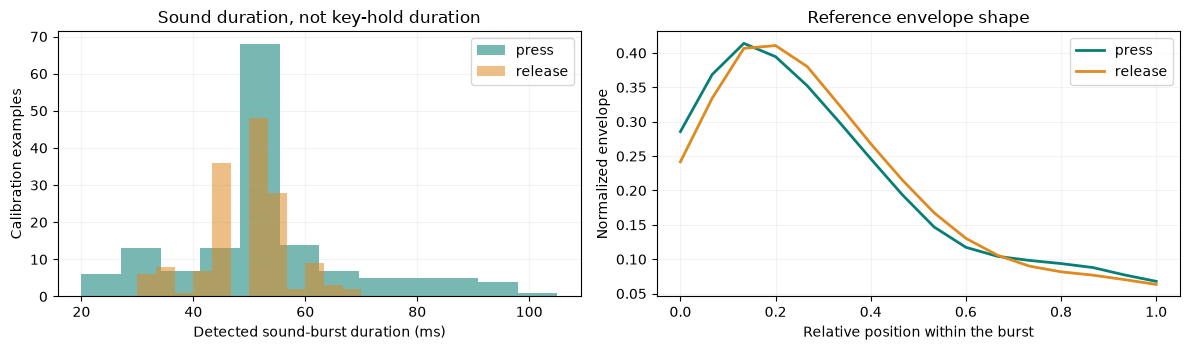

In [78]:
CONFIG=dict(DEFAULT_DSP)
# Optional changes belong here, before calibration/validation:
# CONFIG.update(start_db=8.,end_db=3.,max_burst_ms=120.)
calibration=[s for s in segments if s['role']=='train']
validation=[s for s in segments if s['role']=='validation']
banks={'press':[],'release':[]}; template_records=[]; calibration_runs={}
for s in calibration:
    run=run_dsp(s['x'],s['fs'],CONFIG)
    calibration_runs[s['id']]=run
    pairs=assign_references(run.bursts,s['events'],REFERENCE_TOLERANCE_MS/1000)
    for bi,ei in pairs:
        burst=run.bursts[bi]; ref=s['events'].iloc[ei]; kind=ref.kind
        banks[kind].append(burst['signature'])
        template_records.append(dict(segment=s['id'],kind=kind,reference_time=ref.time,
            detected_time=burst['event']['time'],duration_ms=burst['signature']['duration_ms'],
            peak_excess=burst['signature']['peak_excess']))
    print(s['id'],':',len(run.bursts),'candidate sounds,',len(pairs),'matched references')
rng=np.random.default_rng(SEED)
for kind in banks:
    if not banks[kind]:
        raise ValueError(f"No {kind} reference bursts. Check calibration waveforms/label alignment; try lowering start_db on development data.")
    if len(banks[kind])>MAX_TEMPLATES_PER_CLASS:
        indices=rng.choice(len(banks[kind]),MAX_TEMPLATES_PER_CLASS,replace=False)
        banks[kind]=[banks[kind][i] for i in indices]
template_table=pd.DataFrame(template_records)
print("Stored reference templates:",{k:len(v) for k,v in banks.items()})
duration_summary=template_table.groupby('kind').duration_ms.agg(
    count='count',median_ms='median',mean_ms='mean',std_ms='std',
    p10_ms=lambda a: a.quantile(.10),p90_ms=lambda a:a.quantile(.90))
display(duration_summary.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,3.6))
for kind,color in [('press','#087f76'),('release','#df8a21')]:
    rows=template_table[template_table.kind==kind]
    axes[0].hist(rows.duration_ms,bins=12,alpha=.55,color=color,label=kind)
    mean=np.mean([b['envelope'] for b in banks[kind]],axis=0)
    axes[1].plot(np.linspace(0,1,16),mean,label=kind,color=color,lw=2)
axes[0].set(xlabel='Detected sound-burst duration (ms)',ylabel='Calibration examples',title='Sound duration, not key-hold duration')
axes[1].set(xlabel='Relative position within the burst',ylabel='Normalized envelope',title='Reference envelope shape')
for ax in axes: ax.legend(); ax.grid(alpha=.15)
plt.tight_layout();plt.show()


## 5. Validate acceptance thresholds; keep test audio separate

The detector scans all validation audio, including background sounds. Score and margin thresholds are chosen using validation labels only, then frozen. Unknown events stay visible and count as missed typed events where appropriate. They are not dropped to inflate F1.

Peak timing and sound detection are scored separately from correct press/release typing. Hold estimates additionally require both endpoints of the **same ground-truth key cycle** to match; a plausible number alone is insufficient.


In [79]:
def evaluate_dsp(items,tolerance=REFERENCE_TOLERANCE_MS/1000):
    from scipy.optimize import linear_sum_assignment
    totals={k:dict(tp=0,fp=0,fn=0) for k in ('press','release')}
    det_tp=det_fp=det_fn=unknown=0; duration=0; errors=[]; delays=[]
    confusion=np.zeros((2,3),dtype=int); hold_errors=[]; truth_pairs_total=0; paired_correct=0
    def matching(gt,pp):
        if not len(gt) or not len(pp):return []
        d=np.abs(gt.time.to_numpy()[:,None]-pp.time.to_numpy()[None,:]);valid=d<=tolerance
        penalty=(min(d.shape)+1)*(tolerance+1)
        a,b=linear_sum_assignment(np.where(valid,d,penalty))
        return [(int(i),int(j)) for i,j in zip(a,b) if valid[i,j]]
    for s,events in items:
        gt=s['events'].reset_index(drop=True)
        pp=pd.DataFrame(events,columns=['time','decision_time','kind','press_score','release_score','margin','duration_ms'])
        duration+=len(s['x'])/s['fs']; unknown+=int((pp.kind=='uncertain').sum())
        matches=matching(gt,pp);det_tp+=len(matches);det_fp+=len(pp)-len(matches);det_fn+=len(gt)-len(matches)
        for i,j in matches:
            pred=pp.iloc[j]; ref=gt.iloc[i]
            confusion[['press','release'].index(ref.kind),['press','release','uncertain'].index(pred.kind)]+=1
            errors.append(abs(pred.time-ref.time)*1000);delays.append((pred.decision_time-ref.time)*1000)
        for kind in ('press','release'):
            a=gt[gt.kind==kind].reset_index(drop=True);b=pp[pp.kind==kind].reset_index(drop=True)
            count=len(matching(a,b));totals[kind]['tp']+=count;totals[kind]['fp']+=len(b)-count;totals[kind]['fn']+=len(a)-count
        # Reference key-cycle pairing is used exclusively for evaluation.
        held={};cycles=[]
        for row in gt.itertuples():
            if row.kind=='press':held[row.key]=row.time
            elif row.key in held:
                cycles.append((held.pop(row.key),row.time))
        truth_pairs_total+=len(cycles); used=set()
        for pair in pair_events(events):
            candidates=[(abs(pair['press_time']-a)+abs(pair['release_time']-b),i,a,b)
                        for i,(a,b) in enumerate(cycles) if i not in used
                        and abs(pair['press_time']-a)<=tolerance and abs(pair['release_time']-b)<=tolerance]
            if candidates:
                _,i,a,b=min(candidates);used.add(i);paired_correct+=1
                hold_errors.append(abs(pair['hold_ms']-(b-a)*1000))
    def prf(tp,fp,fn):
        return (tp/(tp+fp) if tp+fp else 0.,tp/(tp+fn) if tp+fn else 0.,2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.)
    out=dict(sound_detection_f1=prf(det_tp,det_fp,det_fn)[2],missed_sounds=det_fn,false_sounds=det_fp,
             false_sounds_per_min=det_fp/max(duration/60,1e-9),uncertain_events=unknown,
             onset_mae_ms=float(np.mean(errors)) if errors else np.nan,
             median_decision_delay_ms=float(np.median(delays)) if delays else np.nan,
             correct_hold_pairs=paired_correct,reference_hold_pairs=truth_pairs_total,
             hold_mae_ms=float(np.mean(hold_errors)) if hold_errors else np.nan)
    for kind,v in totals.items():
        p,r,f=prf(**v);out.update({kind+'_precision':p,kind+'_recall':r,kind+'_f1':f})
    out['macro_f1']=(out['press_f1']+out['release_f1'])/2
    return out,confusion

# Burst segmentation/signatures do not depend on acceptance thresholds, so cache them once.
validation_runs={s['id']:run_dsp(s['x'],s['fs'],CONFIG,banks) for s in validation}
def decisions_at(run,threshold,margin):
    result=[]
    for b in run.bursts:
        e=dict(b['event']);winner='release' if e['release_score']>e['press_score'] else 'press'
        e['kind']=winner if max(e['press_score'],e['release_score'])>=threshold and e['margin']>=margin else 'uncertain'
        result.append(e)
    return result
search=[]
for threshold in (.72,.78,.82,.86,.90,.94):
    for margin in (.005,.01,.02,.04):
        items=[(s,decisions_at(validation_runs[s['id']],threshold,margin)) for s in validation]
        metrics,_=evaluate_dsp(items)
        search.append(dict(threshold=threshold,margin=margin,**metrics))
search_table=pd.DataFrame(search)
# Primary objective: press detection, then combined typing. No test labels used.
best=max(search,key=lambda r:(r['press_f1'],r['macro_f1'],-r['false_sounds'],r['threshold']))
CONFIG.update(score_threshold=best['threshold'],margin_threshold=best['margin'])
print('Frozen score threshold:',CONFIG['score_threshold'],'| margin:',CONFIG['margin_threshold'])
display(search_table.sort_values(['press_f1','macro_f1'],ascending=False).head(6).round(3))


Frozen score threshold: 0.86 | margin: 0.005


,threshold,margin,sound_detection_f1,missed_sounds,false_sounds,false_sounds_per_min,uncertain_events,onset_mae_ms,median_decision_delay_ms,correct_hold_pairs,reference_hold_pairs,hold_mae_ms,press_precision,press_recall,press_f1,release_precision,release_recall,release_f1,macro_f1
4,0.78,0.005,0.985,1,2,1.978,26,4.427,50.854,8,50,7.924,0.455,0.30,0.361,0.690,0.58,0.630,0.496
8,0.82,0.005,0.985,1,2,1.978,26,4.427,50.854,8,50,7.924,0.455,0.30,0.361,0.690,0.58,0.630,0.496
12,0.86,0.005,0.985,1,2,1.978,26,4.427,50.854,8,50,7.924,0.455,0.30,0.361,0.690,0.58,0.630,0.496
16,0.90,0.005,0.985,1,2,1.978,38,4.427,50.854,4,50,9.839,0.455,0.30,0.361,0.567,0.34,0.425,0.393
0,0.72,0.005,0.985,1,2,1.978,25,4.427,50.854,8,50,7.924,0.441,0.30,0.357,0.690,0.58,0.630,0.494
20,0.94,0.005,0.985,1,2,1.978,57,4.427,50.854,2,50,7.479,0.462,0.24,0.316,0.389,0.14,0.206,0.261


## 6. Held-out evaluation and static inspection

This section runs the identical incremental Python algorithm on complete held-out blocks. The browser counterpart is checked against Python during notebook development. Browser playback uses the same frozen parameters and template bank. No exact repeatability of floating-point round-off is promised at a decision threshold.

Small test sets, approximate audio/log synchronization, one-session-per-key collection and sound overlap limit interpretation. When making further changes based on these results, use new recordings for the next independent test.


,held-out DSP result
sound_detection_f1,0.9804
missed_sounds,0.0000
false_sounds,4.0000
false_sounds_per_min,3.9322
uncertain_events,28.0000
onset_mae_ms,5.2535
median_decision_delay_ms,51.9375
correct_hold_pairs,11.0000
reference_hold_pairs,50.0000
hold_mae_ms,7.3106


,predicted press,predicted release,uncertain
actual press,25,14,11
actual release,5,31,14


Confusion table includes matched sound events only; misses/false sounds are reported separately above.


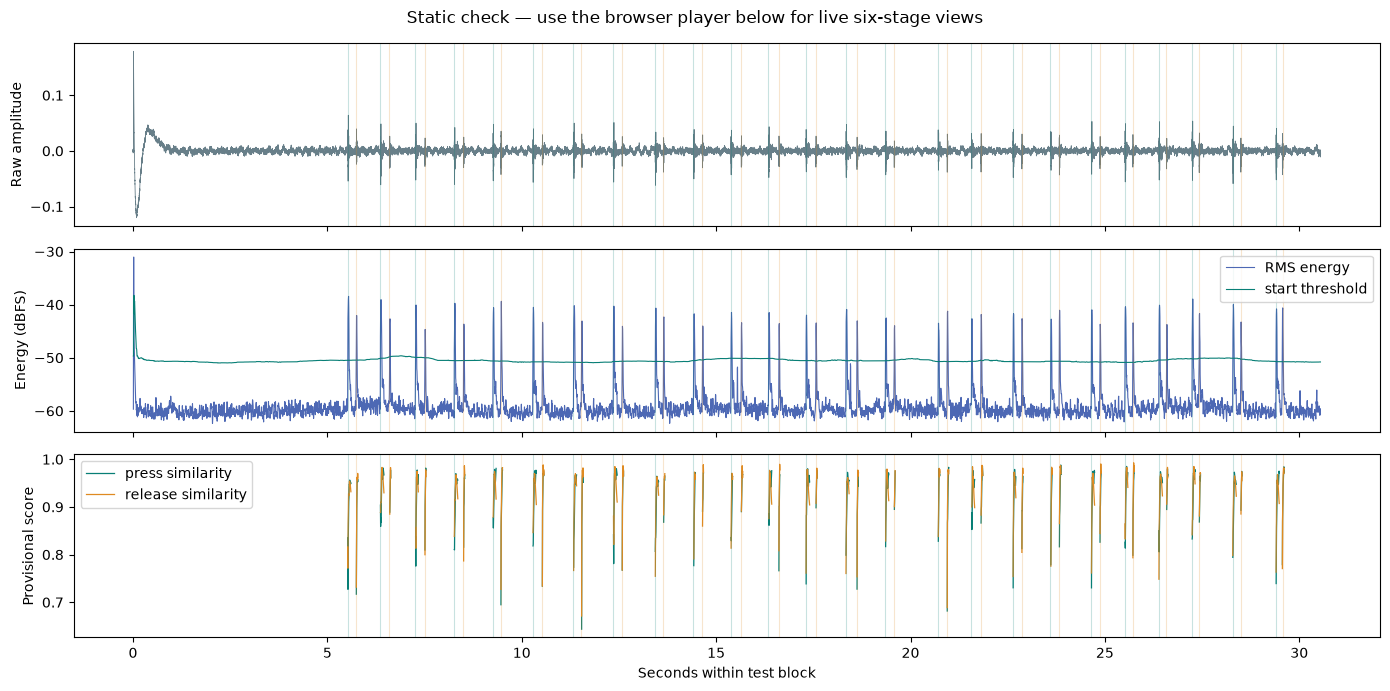

In [80]:
test_runs={};test_items=[]
for s in test_segments:
    run=run_dsp(s['x'],s['fs'],CONFIG,banks)
    test_runs[s['id']]=run;test_items.append((s,run.events))
metrics,confusion=evaluate_dsp(test_items)
display(pd.Series(metrics,name='held-out DSP result').to_frame().round(4))
display(pd.DataFrame(confusion,index=['actual press','actual release'],
                     columns=['predicted press','predicted release','uncertain']))
print('Confusion table includes matched sound events only; misses/false sounds are reported separately above.')
run=test_runs[selected['id']]
fig,axes=plt.subplots(3,1,figsize=(14,7),sharex=True)
x=selected['x'];fs=selected['fs'];stride=max(1,fs//5000)
axes[0].plot(np.arange(0,len(x),stride)/fs,x[::stride],lw=.6,color='#687f89')
frames=pd.DataFrame([{k:r[k] for k in ('end','db','floor','press_score','release_score')} for r in run.frames])
axes[1].plot(frames.end,frames.db,color='#4d68b4',lw=.8,label='RMS energy')
axes[1].plot(frames.end,frames.floor+CONFIG['start_db'],color='#087f76',lw=.8,label='start threshold')
axes[2].plot(frames.end,frames.press_score,color='#087f76',lw=.9,label='press similarity')
axes[2].plot(frames.end,frames.release_score,color='#df8a21',lw=.9,label='release similarity')
for ax in axes:
    for e in selected['events'].itertuples():ax.axvline(e.time,color='#087f76' if e.kind=='press' else '#df8a21',alpha=.22,lw=.8)
axes[0].set_ylabel('Raw amplitude');axes[1].set_ylabel('Energy (dBFS)');axes[2].set_ylabel('Provisional score')
axes[2].set_xlabel('Seconds within test block');axes[1].legend();axes[2].legend()
fig.suptitle('Static check — use the browser player below for live six-stage views')
plt.tight_layout();plt.show()


## 7. Browser engine and player template

The next hidden source cell embeds the browser DSP and dashboard **inside this notebook**, so no companion source files or remote scripts are needed. Expand it if you want to inspect the implementation.

The browser uses its audio playback clock to feed only the samples reached so far into a stateful processor. It calculates filtering, envelopes, spectra, matching and decisions during playback. Frame stepping uses the same processor without playing sound. The optional CSV overlay is held outside the detector class.


In [81]:
JS_ENGINE = "// Stateful browser counterpart of the Python DSP. No reference-label input.\nconst dspUnit = v => {const n=Math.sqrt(v.reduce((s,x)=>s+x*x,0))+1e-12;return v.map(x=>x/n);};\nconst dspDot = (a,b) => a.reduce((s,x,i)=>s+x*b[i],0);\nfunction dspPercentile(v,p){const s=[...v].sort((a,b)=>a-b);if(!s.length)return 0;const z=(s.length-1)*p;const i=Math.floor(z);return s[i]+(s[Math.min(i+1,s.length-1)]-s[i])*(z-i);}\nfunction dspInterp(v,n){if(v.length===1)return Array(n).fill(v[0]);return Array.from({length:n},(_,i)=>{const z=i*(v.length-1)/(n-1),j=Math.floor(z);return v[j]+(v[Math.min(j+1,v.length-1)]-v[j])*(z-j);});}\nfunction dspFFT(input,n){\n const re=new Float64Array(n),im=new Float64Array(n);re.set(input);\n for(let i=1,j=0;i<n;i++){let bit=n>>1;for(;j&bit;bit>>=1)j^=bit;j^=bit;if(i<j){const v=re[i];re[i]=re[j];re[j]=v;}}\n for(let len=2;len<=n;len<<=1){const angle=-2*Math.PI/len,cr=Math.cos(angle),ci=Math.sin(angle);\n  for(let a=0;a<n;a+=len){let wr=1,wi=0;for(let j=0;j<len/2;j++){\n   const u=a+j,v=u+len/2,tr=re[v]*wr-im[v]*wi,ti=re[v]*wi+im[v]*wr;\n   re[v]=re[u]-tr;im[v]=im[u]-ti;re[u]+=tr;im[u]+=ti;\n   const next=wr*cr-wi*ci;wi=wr*ci+wi*cr;wr=next;\n  }}\n }\n return Array.from({length:n/2+1},(_,i)=>re[i]*re[i]+im[i]*im[i]);\n}\nfunction dspSignature(rows){\n const maxdb=Math.max(...rows.map(r=>r.db));const amp=rows.map(r=>Math.pow(10,(r.db-maxdb)/20));\n const weights=amp.map(x=>x*x),total=weights.reduce((s,x)=>s+x,0);\n let spectrum=Array(16).fill(0);rows.forEach((r,i)=>r.spectrum.forEach((v,j)=>spectrum[j]+=v*weights[i]/total));\n const mean=spectrum.reduce((s,x)=>s+x,0)/16;spectrum=dspUnit(spectrum.map(x=>x-mean));\n return {spectrum,envelope:dspUnit(dspInterp(amp,16)),duration_ms:(rows.at(-1).end-rows[0].end)*1000+rows[0].window_ms,\n   peak_excess:Math.max(...rows.map(r=>r.excess)),peak_db:maxdb};\n}\nfunction dspScores(s,banks){return ['press','release'].map(kind=>{\n let best=0;for(const t of banks[kind]||[]){\n  const spectral=(dspDot(s.spectrum,t.spectrum)+1)/2,envelope=dspDot(s.envelope,t.envelope);\n  const amplitude=Math.exp(-Math.abs(s.peak_excess-t.peak_excess)/15);\n  const duration=Math.exp(-Math.abs(Math.log(Math.max(s.duration_ms,1)/Math.max(t.duration_ms,1))));\n  best=Math.max(best,.55*spectral+.25*envelope+.10*amplitude+.10*duration);\n }return best;});}\nclass LiveDSP {\n constructor(fs,config,banks){\n  this.fs=fs;this.c=config;this.banks=banks;this.win=Math.round(fs*config.window_ms/1000);this.hop=Math.round(fs*config.hop_ms/1000);\n  this.nfft=2**Math.ceil(Math.log2(this.win));this.a=Math.exp(-2*Math.PI*config.highpass_hz/fs);\n  this.previousRaw=0;this.previousFiltered=0;this.filtered=[];this.rawPending=[];this.received=0;\n  this.noise=[];this.recentDB=[];this.active=null;this.quiet=0;this.lastStart=-Infinity;\n  this.frames=[];this.events=[];this.bursts=[];this.filteredAll=[];\n  this.window=Array.from({length:this.win},(_,i)=>.5-.5*Math.cos(2*Math.PI*i/(this.win-1)));\n  const lo=Math.log(100),hi=Math.log(Math.min(12000,.49*fs));this.edges=Array.from({length:17},(_,i)=>Math.exp(lo+(hi-lo)*i/16));\n }\n finishBurst(decision,reason){\n  if(!this.active)return null;\n  const body=this.quiet>0&&this.quiet<this.active.length?this.active.slice(0,-this.quiet):this.active;\n  this.active=null;this.quiet=0;const s=dspSignature(body),sc=dspScores(s,this.banks);\n  const margin=Math.abs(sc[0]-sc[1]);let kind=sc[1]>sc[0]?'release':'press';\n  if(Math.max(...sc)<this.c.score_threshold||margin<this.c.margin_threshold)kind='uncertain';\n  const event={time:Math.max(0,body[0].end-this.win/this.fs/2),end:body.at(-1).end,decision_time:decision,\n   kind,press_score:sc[0],release_score:sc[1],margin,duration_ms:s.duration_ms,peak_excess:s.peak_excess,close_reason:reason};\n  this.events.push(event);this.bursts.push({event,signature:s});return event;\n }\n push(samples){\n  for(const x of samples)this.rawPending.push(x);let consumed=0,emitted=[];\n  while(this.rawPending.length-consumed>=this.hop){\n   for(let i=0;i<this.hop;i++){\n    const raw=this.rawPending[consumed+i];const y=this.a*(this.previousFiltered+raw-this.previousRaw);\n    this.previousRaw=raw;this.previousFiltered=y;this.filtered.push(y);this.filteredAll.push(y);\n   }\n   consumed+=this.hop;if(this.filtered.length>this.win)this.filtered=this.filtered.slice(-this.win);\n   this.received+=this.hop;if(this.filtered.length<this.win)continue;\n   const end=this.received/this.fs;\n   const db=20*Math.log10(Math.sqrt(this.filtered.reduce((s,x)=>s+x*x,0)/this.win)+1e-10);\n   const floor=this.noise.length?dspPercentile(this.noise,.2):db,excess=db-floor;\n   const rise=this.recentDB.length?db-Math.min(...this.recentDB):0;\n   const power=dspFFT(this.filtered.map((v,i)=>v*this.window[i]),this.nfft),band=Array(16).fill(1e-15);\n   for(let k=0;k<power.length;k++){const hz=k*this.fs/this.nfft;\n    for(let b=0;b<16;b++)if(hz>=this.edges[b]&&hz<this.edges[b+1]){band[b]+=power[k];break;}\n   }\n   const sum=band.reduce((s,x)=>s+x,0),spectrum=band.map(x=>Math.sqrt(x/sum));\n   const row={end,db,floor,excess,rise,spectrum,window_ms:this.win/this.fs*1000,active:false,press_score:null,release_score:null};\n   const warm=end*1000<this.c.warmup_ms;\n   const trigger=!warm&&excess>=this.c.start_db&&rise>=this.c.rise_db&&end-this.lastStart>=this.c.min_spacing_ms/1000;\n   if(this.active){\n    const elapsed=(end-this.active[0].end)*1000;\n    if(trigger&&rise>=this.c.split_rise_db&&elapsed>=this.c.split_min_ms){const e=this.finishBurst(end,'new onset');if(e)emitted.push(e);}\n    else{\n     this.active.push(row);this.quiet=excess<=this.c.end_db?this.quiet+1:0;\n     if(this.quiet*this.c.hop_ms>=this.c.quiet_ms||elapsed>=this.c.max_burst_ms){const e=this.finishBurst(end,this.quiet?'quiet':'duration limit');if(e)emitted.push(e);}\n    }\n   }\n   if(this.active===null&&trigger){this.active=[row];this.quiet=0;this.lastStart=end;}\n   row.active=this.active!==null;\n   if(this.active&&Object.keys(this.banks).length){const sc=dspScores(dspSignature(this.active),this.banks);row.press_score=sc[0];row.release_score=sc[1];}\n   if(warm||(!row.active&&excess<this.c.start_db)){\n    this.noise.push(db);const n=Math.max(10,Math.floor(this.c.noise_history_ms/this.c.hop_ms));if(this.noise.length>n)this.noise.shift();\n   }\n   this.recentDB.push(db);if(this.recentDB.length>4)this.recentDB.shift();this.frames.push(row);\n  }\n  this.rawPending=this.rawPending.slice(consumed);return emitted;\n }\n}\n"
PLAYER_TEMPLATE = '<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Keyboard Audio · DSP Live Lab</title>\n<style>\n:root{--ink:#182d37;--muted:#61747e;--bg:#edf2f3;--line:#dae4e6;--press:#087f76;--release:#df8a21;--unknown:#7a8395;--blue:#4d68b4}*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.5 system-ui,-apple-system,Segoe UI,sans-serif}main{max-width:1440px;margin:auto;padding:26px 30px 40px}.eyebrow{font-size:11px;font-weight:750;letter-spacing:1.8px;color:var(--press)}h1{font-size:30px;letter-spacing:-1px;margin:3px 0 5px}h2{font-size:15px;margin:0}.sub{color:var(--muted);margin:0 0 18px;max-width:1000px}.toolbar,.panel{background:white;border:1px solid var(--line);border-radius:13px}.toolbar{padding:16px 18px;box-shadow:0 4px 20px #183c4810;position:sticky;top:0;z-index:3}.row{display:flex;align-items:center;gap:9px;flex-wrap:wrap}.row+.row{margin-top:12px}button,select,.filelabel{font:inherit;border:1px solid #c8d7db;border-radius:7px;padding:8px 13px;background:white;color:var(--ink);cursor:pointer}button.primary{background:var(--press);color:white;border-color:var(--press);font-weight:700}button:hover,.filelabel:hover{filter:brightness(.97)}button:disabled{opacity:.45;cursor:default}input[type=range]{accent-color:var(--press)}#seek{flex:1;min-width:170px}#clock{font-variant-numeric:tabular-nums;font-weight:700;min-width:125px}.small{font-size:12px;color:var(--muted)}.spacer{flex:1}.badge{background:#edf7f5;border-radius:20px;padding:4px 10px;color:var(--press);font-size:12px;font-weight:650}#filename{font-weight:600;max-width:520px;overflow:hidden;text-overflow:ellipsis;white-space:nowrap}.status{margin:12px 0;display:flex;gap:14px;align-items:center;flex-wrap:wrap}#status{color:var(--muted)}.counter{background:white;border:1px solid var(--line);padding:5px 11px;border-radius:6px;font-variant-numeric:tabular-nums}.grid{display:grid;grid-template-columns:1fr 1fr;gap:14px}.panel{padding:15px 17px;min-width:0;transition:border-color .15s,box-shadow .15s}.panel.focus{border-color:var(--press);box-shadow:0 0 0 2px #087f7620}.head{display:flex;gap:10px;align-items:center;margin-bottom:4px}.number{font-size:12px;color:var(--press);background:#e8f5f2;border-radius:6px;min-width:25px;padding:2px 5px;text-align:center;font-weight:750}.desc{font-size:12px;color:var(--muted);margin:0 0 6px;min-height:34px}.legend{display:flex;gap:12px;font-size:11px;color:var(--muted);margin-top:2px;flex-wrap:wrap}.legend i{display:inline-block;width:8px;height:8px;border-radius:50%;margin-right:4px}.chart{width:100%;height:150px;display:block}.panel.wide{grid-column:1/-1}#events{max-height:200px;overflow:auto}table{border-collapse:collapse;width:100%;font-size:12px;font-variant-numeric:tabular-nums}th,td{text-align:right;padding:7px 8px;border-bottom:1px solid #e9eff0}th:first-child,td:first-child{text-align:left}th{position:sticky;top:0;background:white;color:var(--muted);font-weight:600}.tag{font-size:11px;border-radius:4px;padding:2px 6px;background:#eef2f3}.tag.press{color:var(--press);background:#e5f5ef}.tag.release{color:#9e5700;background:#fff1dc}.tag.uncertain{color:#657081}details{margin-top:16px;color:var(--muted);background:white;padding:12px 16px;border-radius:10px;border:1px solid var(--line)}summary{cursor:pointer;color:var(--ink);font-weight:650}#error{display:none;background:#fff0ee;border:1px solid #ebc3b9;padding:12px;border-radius:8px;color:#803b28;margin:12px 0}.stepnote{font-size:12px;color:var(--press);margin-top:8px}#mode-label{font-size:12px}.mono{font-family:ui-monospace,monospace}@media(max-width:850px){main{padding:15px}.grid{grid-template-columns:1fr}.panel.wide{grid-column:auto}.toolbar{position:relative}.chart{height:155px}h1{font-size:25px}}@media(prefers-reduced-motion:reduce){*{scroll-behavior:auto}}\n</style></head><body><main>\n<div class="eyebrow">ACOUSTIC KEYSTROKES / SIGNAL PROCESSING ONLY</div><h1>Keyboard Audio · Live DSP Lab</h1>\n<p class="sub">Press Play to hear the WAV and process it as it advances. Every stage uses only samples that have reached the playback cursor. No key-event timestamps enter the detector.</p>\n<div id="error"></div>\n<section class="toolbar"><div class="row">\n<button id="play" class="primary">▶ Play</button><button id="restart">↺ Restart</button><button id="step">Step +5 ms</button><button id="next">Next burst</button>\n<select id="clip" aria-label="Bundled WAV recordings"></select><button id="random">Random WAV</button>\n<label class="filelabel">Choose WAV…<input id="file" type="file" accept=".wav,audio/wav" hidden></label>\n<div class="spacer"></div><span class="badge">Causal · audio only</span>\n</div><div class="row"><span id="clock">0.00 / 0.00 s</span><input id="seek" type="range" min="0" max="1" step=".005" value="0" aria-label="Playback position">\n<label class="small">Speed <select id="speed"><option value=".5">0.5×</option><option value="1" selected>1×</option><option value="1.5">1.5×</option></select></label>\n<label class="small">Listen gain <input id="volume" type="range" min="0" max="5" value="1" step=".1" style="width:80px"></label>\n</div><div class="row"><span id="filename"></span><span id="clipinfo" class="small"></span><div class="spacer"></div>\n<label id="mode-label"><input type="checkbox" id="pressonly"> Show press detections only</label>\n<label class="small"><input type="checkbox" id="truth"> Show CSV reference labels (display only)</label>\n</div><div class="stepnote" id="explain">Ready. Step processes a small frame silently; Next burst advances until a candidate sound is complete.</div></section>\n<div class="status"><span id="status">Waiting for playback</span><span class="counter" id="counts">Press 0 · Release 0 · Uncertain 0</span><span class="small" id="progress">0 processed frames</span></div>\n<section class="grid">\n<div class="panel" data-stage="1"><div class="head"><span class="number">01</span><h2>Raw microphone signal</h2></div><p class="desc">Original digital amplitude. The cursor reveals only audio already reached.</p><canvas id="raw" class="chart"></canvas><div class="legend">No whole-file gain normalization · listening gain does not affect processing</div></div>\n<div class="panel" data-stage="2"><div class="head"><span class="number">02</span><h2>High-pass filtering</h2></div><p class="desc">Remove DC and low-frequency drift while keeping filter state between frames.</p><canvas id="filtered" class="chart"></canvas><div class="legend" id="filterlegend"></div></div>\n<div class="panel" data-stage="3"><div class="head"><span class="number">03</span><h2>Energy envelope → sound bursts</h2></div><p class="desc">A sudden rise above the rolling noise floor opens a burst; a lower threshold confirms its end.</p><canvas id="energy" class="chart"></canvas><div class="legend"><span><i style="background:#4d68b4"></i>RMS energy</span><span><i style="background:#7f9299"></i>Noise floor</span><span><i style="background:#087f76"></i>Start threshold</span><span><i style="background:#df8a21"></i>End threshold</span></div></div>\n<div class="panel" data-stage="4"><div class="head"><span class="number">04</span><h2>Frequency-shape inspection</h2></div><p class="desc">Current spectral contrast across 16 bands, compared with the calibration template means.</p><canvas id="spectrum" class="chart"></canvas><div class="legend"><span><i style="background:#4d68b4"></i>Current sound</span><span><i style="background:#087f76"></i>Press reference mean</span><span><i style="background:#df8a21"></i>Release reference mean</span></div></div>\n<div class="panel" data-stage="5"><div class="head"><span class="number">05</span><h2>Press / release template scores</h2></div><p class="desc">Match spectral shape, envelope, relative energy and burst duration. Partial-burst scores are provisional.</p><canvas id="scores" class="chart"></canvas><div class="legend"><span><i style="background:#087f76"></i>Press score</span><span><i style="background:#df8a21"></i>Release score</span><span><i style="background:#7a8395"></i>Acceptance threshold</span></div></div>\n<div class="panel" data-stage="6"><div class="head"><span class="number">06</span><h2>Event decisions & hold estimate</h2></div><p class="desc">Emit after a burst is complete. Close scores stay uncertain; hold estimates require an isolated press/release pair.</p><canvas id="decisions" class="chart"></canvas><div class="legend"><span><i style="background:#087f76"></i>Press</span><span><i style="background:#df8a21"></i>Release</span><span><i style="background:#7a8395"></i>Uncertain</span><span id="hold">No confirmed hold estimate</span></div></div>\n<div class="panel wide"><div class="head"><span class="number">↳</span><h2>Live event log</h2><div class="spacer"></div><button id="download">Download event CSV</button></div><p class="desc">Onset time is estimated from audio. Decision time is when enough audio had arrived to emit the event; it is later.</p><div id="events"><table><thead><tr><th>Decision</th><th>Onset (s)</th><th>Emitted (s)</th><th>Sound (ms)</th><th>Press score</th><th>Release score</th><th>Margin</th></tr></thead><tbody id="eventrows"><tr><td colspan="7" class="small">Press Play or Next burst to begin.</td></tr></tbody></table></div></div>\n</section>\n<details><summary>How to use and interpret this player</summary><p><b>Play</b> runs audio and incremental processing. <b>Pause</b> freezes both. <b>Step</b> advances one processing hop with no sound. <b>Next burst</b> silently processes until one new candidate burst closes. <b>Restart</b> clears the detector state. Seeking recomputes the prefix from the start, keeping the algorithm causal.</p><p>The browser computes the DSP stages during playback; these are not pre-rendered prediction traces. The full WAV is loaded for listening, but the DSP receives only the prefix reached by the playback clock. This is a real-time WAV replay, not a live microphone input. Keep this tab visible; browser background-tab throttling can delay displays.</p><p>Ground-truth lines are an optional visual overlay and do not enter the DSP. A high similarity is not a probability of correctness. Press-only mode hides other event types; it does not convert uncertain sounds into presses. Multiple peaks can belong to one burst. Duration limits group sound ringing, not the time a key is held.</p><p>Key-hold estimation assumes one key at a time. An uncertain burst or another press breaks an unmatched sequence. Never infer a release just because the average hold time has elapsed. The first <span id="warmup"></span> ms establish the noise floor; events during that warm-up can be missed. Listen gain changes only playback volume.</p><p>Calibration/test separation: <span id="splitnote"></span>. Loading a new WAV uses the existing templates. A file from calibration is a demonstration, not an independent test. All audio stays inside this local page; no network services or machine-learning models are used.</p></details>\n</main>\n<script id="payload" type="application/json">__PAYLOAD__</script>\n<script>\n__ENGINE__\nconst DATA=JSON.parse(document.getElementById(\'payload\').textContent);\nconst $=id=>document.getElementById(id), COLORS={press:\'#087f76\',release:\'#df8a21\',uncertain:\'#7a8395\'};\nlet assets=DATA.audio, selected=0, samples=null,fs=48000,refs=[],processor=null,buffer=null,ctx=null,gain=null,source=null;\nlet position=0,playing=false,startedAt=0,anchor=0,lastRendered=0,rate=1,processed=0,raf=0,playGeneration=0;\nfunction showError(e){$(\'error\').style.display=\'block\';$(\'error\').textContent=String(e.message||e);console.error(e);}\nfunction decodePCM(b64){const s=atob(b64),bytes=new Uint8Array(s.length);for(let i=0;i<s.length;i++)bytes[i]=s.charCodeAt(i);return new Float32Array(bytes.buffer);}\nfunction currentPosition(){return playing?Math.min(samples.length/fs,anchor+Math.max(0,ctx.currentTime-startedAt)*rate):position;}\nfunction stopSource(){playGeneration++;if(source){source.onended=null;try{source.stop();}catch(e){}source.disconnect();source=null;}}\nfunction resetProcessor(){processor=new LiveDSP(fs,DATA.config,DATA.banks);processed=0;lastRendered=0;}\nfunction feedUntil(seconds){const target=Math.min(samples.length,Math.floor(seconds*fs));const step=Math.max(1,Math.round(fs*.020));\n while(processed<target){const end=Math.min(target,processed+step);processor.push(samples.subarray(processed,end));processed=end;}}\nfunction pause(){position=currentPosition();playing=false;cancelAnimationFrame(raf);stopSource();$(\'play\').textContent=\'▶ Play\';feedUntil(position);render();}\nfunction ensureContext(){if(!ctx){ctx=new (window.AudioContext||window.webkitAudioContext)();gain=ctx.createGain();gain.connect(ctx.destination);}return ctx;}\nasync function play(){try{\n if(playing){pause();return;}if(position>=samples.length/fs-.001){position=0;resetProcessor();}\n ensureContext();await ctx.resume();buffer=ctx.createBuffer(1,samples.length,fs);buffer.copyToChannel(samples,0);\n source=ctx.createBufferSource();source.buffer=buffer;source.playbackRate.value=rate;source.connect(gain);gain.gain.value=Number($(\'volume\').value);\n anchor=position;startedAt=ctx.currentTime+.035;const generation=++playGeneration;playing=true;\n source.onended=()=>{if(generation!==playGeneration)return;position=samples.length/fs;playing=false;feedUntil(position);$(\'play\').textContent=\'▶ Play\';render();};\n source.start(startedAt,position);$(\'play\').textContent=\'Ⅱ Pause\';$(\'explain\').textContent=\'Processing incoming audio: filtering → energy → bursts → spectrum → templates → decisions.\';\n raf=requestAnimationFrame(tick);\n }catch(e){playing=false;showError(e);}}\nfunction tick(timestamp){if(!playing)return;position=currentPosition();feedUntil(position);if(timestamp-lastRendered>65){render();lastRendered=timestamp;}if(playing)raf=requestAnimationFrame(tick);}\nfunction choose(index){if(playing)pause();stopSource();selected=index;const item=assets[index];samples=decodePCM(item.pcm);fs=item.fs;refs=item.references||[];position=0;buffer=null;resetProcessor();\n $(\'filename\').textContent=item.name;$(\'clipinfo\').textContent=`${(samples.length/fs).toFixed(2)} s · ${fs.toLocaleString()} Hz · ${item.role}`;\n $(\'seek\').max=samples.length/fs;$(\'seek\').step=DATA.config.hop_ms/1000;$(\'clip\').value=index;$(\'truth\').disabled=!refs.length;if(!refs.length)$(\'truth\').checked=false;\n $(\'step\').textContent=`Step +${DATA.config.hop_ms} ms`;$(\'explain\').textContent=\'Ready. Press Play for live processing, or Next burst to inspect one sound at a time.\';render();}\nfunction fillClips(){const e=$(\'clip\');e.innerHTML=\'\';assets.forEach((a,i)=>{const o=document.createElement(\'option\');o.value=i;o.textContent=a.name;e.appendChild(o);});}\nfunction setupCanvas(id){const c=$(id),rect=c.getBoundingClientRect(),dpr=window.devicePixelRatio||1;const w=Math.max(250,Math.round(rect.width)),h=Math.round(rect.height);\n if(c.width!==Math.round(w*dpr)||c.height!==Math.round(h*dpr)){c.width=Math.round(w*dpr);c.height=Math.round(h*dpr);}const g=c.getContext(\'2d\');g.setTransform(dpr,0,0,dpr,0,0);g.clearRect(0,0,w,h);return{g,w,h};}\nfunction grid(id,min,max,units){const c=setupCanvas(id),{g,w,h}=c;const left=43,right=12,top=10,bottom=23;const x0=left,x1=w-right,y0=top,y1=h-bottom;\n g.font=\'10px system-ui\';g.lineWidth=1;for(let i=0;i<3;i++){const y=y0+(y1-y0)*i/2;g.strokeStyle=\'#e8eef0\';g.beginPath();g.moveTo(x0,y);g.lineTo(x1,y);g.stroke();g.fillStyle=\'#71838c\';g.fillText((max-(max-min)*i/2).toFixed(units===\'dB\'?0:Math.abs(max)<.1?3:2),1,y+3);}\n return {...c,x0,x1,y0,y1,Y:v=>y1-(v-min)/(max-min)*(y1-y0)};}\nfunction timeGrid(id,min,max){const c=grid(id,min,max,min<-2?\'dB\':\'\');const now=position,start=Math.max(0,now-4),end=Math.max(4,now);c.start=start;c.end=end;c.X=t=>c.x0+(t-start)/(end-start)*(c.x1-c.x0);\n c.g.fillStyle=\'#71838c\';for(let i=0;i<5;i++){const t=start+(end-start)*i/4;c.g.fillText(t.toFixed(1)+\'s\',c.X(t)-7,c.h-4);}return c;}\nfunction line(c,rows,get,color,width=1.5,dash=[]){const {g}=c;g.strokeStyle=color;g.lineWidth=width;g.setLineDash(dash);g.beginPath();let open=false;\n for(const r of rows){if(r.end<c.start||r.end>position)continue;const v=get(r);if(v===null||!Number.isFinite(v)){open=false;continue;}const x=c.X(r.end),y=c.Y(v);if(!open){g.moveTo(x,y);open=true;}else g.lineTo(x,y);}g.stroke();g.setLineDash([]);}\nfunction plotWave(id,signal,upTo,color){let scale=.005;const lo=Math.max(0,Math.floor(Math.max(0,position-4)*fs)),hi=Math.min(upTo,Math.floor(position*fs),signal.length);for(let i=lo;i<hi;i++)scale=Math.max(scale,Math.abs(signal[i]));scale*=1.1;const c=timeGrid(id,-scale,scale),{g}=c;\n const first=Math.max(0,Math.floor(c.start*fs)),last=Math.min(upTo,Math.floor(position*fs),signal.length),pixels=Math.max(1,Math.floor(c.x1-c.x0));g.strokeStyle=color;g.lineWidth=.85;\n for(let p=0;p<pixels;p++){const a=Math.max(first,Math.floor((c.start+(c.end-c.start)*p/pixels)*fs)),b=Math.min(last,Math.ceil((c.start+(c.end-c.start)*(p+1)/pixels)*fs));if(a>=b)continue;\n  let lo=Infinity,hi=-Infinity;for(let k=a;k<b;k++){lo=Math.min(lo,signal[k]);hi=Math.max(hi,signal[k]);}const x=c.x0+p;g.beginPath();g.moveTo(x,c.Y(lo));g.lineTo(x,c.Y(hi));g.stroke();}\n truthOverlay(c);}\nfunction truthOverlay(c){if(!$(\'truth\').checked)return;const {g}=c;g.save();g.globalAlpha=.27;for(const e of refs){if(e.time<c.start||e.time>position)continue;g.strokeStyle=COLORS[e.kind];g.beginPath();g.moveTo(c.X(e.time),c.y0);g.lineTo(c.X(e.time),c.y1);g.stroke();}g.restore();}\nfunction plotEnergy(){const rows=processor.frames.filter(r=>r.end>=Math.max(0,position-4));let min=-90,max=-10;\n if(rows.length){min=Math.floor(Math.min(...rows.map(r=>r.floor),...rows.map(r=>r.db))/10)*10-5;max=Math.ceil(Math.max(...rows.map(r=>r.db),...rows.map(r=>r.floor+DATA.config.start_db))/10)*10+5;}\n const c=timeGrid(\'energy\',min,max);for(const r of rows)if(r.active){c.g.fillStyle=\'#087f7610\';c.g.fillRect(c.X(r.end),c.y0,Math.max(1,(c.x1-c.x0)*DATA.config.hop_ms/4000),c.y1-c.y0);}\n line(c,rows,r=>r.db,\'#4d68b4\',1.6);line(c,rows,r=>r.floor,\'#87979e\',1,[3,3]);line(c,rows,r=>r.floor+DATA.config.start_db,COLORS.press,1,[5,3]);line(c,rows,r=>r.floor+DATA.config.end_db,COLORS.release,1,[3,3]);truthOverlay(c);}\nfunction templateMean(kind){const b=DATA.banks[kind]||[];if(!b.length)return Array(16).fill(0);return Array.from({length:16},(_,i)=>b.reduce((s,t)=>s+t.spectrum[i],0)/b.length);}\nfunction plotSpectrum(){const c=grid(\'spectrum\',-.65,.85,\'\'),{g}=c,row=processor.frames.at(-1);const current=row?dspUnit(row.spectrum.map(x=>x-row.spectrum.reduce((s,v)=>s+v,0)/16)):Array(16).fill(0);\n const press=templateMean(\'press\'),release=templateMean(\'release\'),dx=(c.x1-c.x0)/16;\n for(let i=0;i<16;i++){const x=c.x0+(i+.5)*dx;g.fillStyle=\'#4d68b499\';g.fillRect(x-dx*.30,Math.min(c.Y(0),c.Y(current[i])),dx*.6,Math.max(1,Math.abs(c.Y(current[i])-c.Y(0))));}\n for(const [v,color] of [[press,COLORS.press],[release,COLORS.release]]){g.strokeStyle=color;g.lineWidth=1.5;g.beginPath();v.forEach((y,i)=>i?g.lineTo(c.x0+(i+.5)*dx,c.Y(y)):g.moveTo(c.x0+.5*dx,c.Y(y)));g.stroke();}\n g.fillStyle=\'#71838c\';g.fillText(\'100 Hz\',c.x0,c.h-4);g.fillText(\'log-spaced frequency bands\',c.x0+70,c.h-4);g.fillText(Math.round(Math.min(12000,.49*fs)/1000)+\' kHz\',c.x1-35,c.h-4);}\nfunction visibleEvents(){return processor.events.filter(e=>!$(\'pressonly\').checked||e.kind===\'press\');}\nfunction plotScores(){const c=timeGrid(\'scores\',0,1);line(c,processor.frames,r=>r.press_score,COLORS.press);line(c,processor.frames,r=>r.release_score,COLORS.release);\n c.g.strokeStyle=\'#87919e\';c.g.setLineDash([4,4]);c.g.beginPath();c.g.moveTo(c.x0,c.Y(DATA.config.score_threshold));c.g.lineTo(c.x1,c.Y(DATA.config.score_threshold));c.g.stroke();c.g.setLineDash([]);\n for(const e of visibleEvents())if(e.time>=c.start&&e.time<=position){c.g.fillStyle=COLORS[e.kind];c.g.beginPath();c.g.arc(c.X(e.time),c.Y(Math.max(e.press_score,e.release_score)),3,0,Math.PI*2);c.g.fill();}truthOverlay(c);}\nfunction holdPairs(){let pending=null,out=[];for(const e of processor.events){if(e.kind===\'press\')pending=e;else if(e.kind===\'release\'&&pending){if(e.time>pending.time)out.push({press:pending.time,release:e.time,hold:(e.time-pending.time)*1000});pending=null;}else if(e.kind===\'uncertain\')pending=null;}return out;}\nfunction plotDecisions(){const c=timeGrid(\'decisions\',0,3),{g}=c;const levels={press:2.4,release:1.5,uncertain:.6};g.fillStyle=\'#71838c\';g.font=\'10px system-ui\';\n for(const [kind,y] of Object.entries(levels))g.fillText(kind,c.x0+4,c.Y(y)-7);\n for(const e of visibleEvents())if(e.time>=c.start&&e.time<=position){g.strokeStyle=COLORS[e.kind];g.fillStyle=COLORS[e.kind];g.beginPath();g.moveTo(c.X(e.time),c.Y(.2));g.lineTo(c.X(e.time),c.Y(levels[e.kind]));g.stroke();g.beginPath();g.arc(c.X(e.time),c.Y(levels[e.kind]),4,0,Math.PI*2);g.fill();}\n truthOverlay(c);const pairs=holdPairs(),last=pairs.at(-1);$(\'hold\').textContent=last?`Last paired hold: ${last.hold.toFixed(1)} ms`:\'No confirmed hold estimate\';}\nfunction updateLog(){const rows=visibleEvents().slice(-30).reverse();$(\'eventrows\').innerHTML=rows.map(e=>`<tr><td><span class="tag ${e.kind}">${e.kind}</span></td><td>${e.time.toFixed(3)}</td><td>${e.decision_time.toFixed(3)}</td><td>${e.duration_ms.toFixed(1)}</td><td>${e.press_score.toFixed(3)}</td><td>${e.release_score.toFixed(3)}</td><td>${e.margin.toFixed(3)}</td></tr>`).join(\'\')||\'<tr><td colspan="7" class="small">No completed events yet.</td></tr>\';\n const counts={press:0,release:0,uncertain:0};processor.events.forEach(e=>counts[e.kind]++);$(\'counts\').textContent=`Press ${counts.press} · Release ${counts.release} · Uncertain ${counts.uncertain}`;}\nfunction render(){if(!processor||!samples)return;$(\'clock\').textContent=`${position.toFixed(2)} / ${(samples.length/fs).toFixed(2)} s`;$(\'seek\').value=position;\n $(\'status\').textContent=playing?\'Playing · streaming DSP\':position>=samples.length/fs-.001?\'Finished · pending final burst is not fabricated\':\'Paused / ready\';$(\'progress\').textContent=`${processor.frames.length.toLocaleString()} processed frames · ${processor.active?\'burst open\':\'listening\'}`;\n plotWave(\'raw\',samples,processed,\'#6b7c86\');plotWave(\'filtered\',processor.filteredAll,processor.filteredAll.length,\'#4d68b4\');plotEnergy();plotSpectrum();plotScores();plotDecisions();updateLog();\n window.dspLiveState={position,processed,playing,frames:processor.frames.length,events:processor.events,pending:processor.active!==null,fs};}\n$(\'play\').onclick=play;$(\'restart\').onclick=()=>{if(playing)pause();stopSource();position=0;resetProcessor();$(\'play\').textContent=\'▶ Play\';render();};\n$(\'step\').onclick=()=>{if(playing)pause();position=Math.min(samples.length/fs,position+DATA.config.hop_ms/1000);feedUntil(position);$(\'explain\').textContent=\'One processing hop advanced. The first complete analysis window needs more than one hop.\';render();};\n$(\'next\').onclick=()=>{if(playing)pause();const count=processor.events.length;let loops=0;while(processor.events.length===count&&position<samples.length/fs&&loops<20000){position=Math.min(samples.length/fs,position+DATA.config.hop_ms/1000);feedUntil(position);loops++;}render();$(\'explain\').textContent=processor.events.length>count?\'New candidate completed. Inspect both template scores and the event log.\':\'Reached the end. An unfinished final burst stays pending.\';};\n$(\'seek\').onpointerdown=()=>{if(playing)pause();};\n$(\'seek\').onchange=()=>{const target=Number($(\'seek\').value);if(playing)pause();position=target;resetProcessor();feedUntil(position);render();};\n$(\'speed\').onchange=()=>{const resume=playing;if(resume)pause();rate=Number($(\'speed\').value);if(resume)play();};\n$(\'volume\').oninput=()=>{if(gain)gain.gain.value=Number($(\'volume\').value);};\n$(\'clip\').onchange=()=>choose(Number($(\'clip\').value));$(\'random\').onclick=()=>{if(assets.length<2){choose(0);$(\'explain\').textContent=\'Only one bundled test WAV. Choose WAV to load another recording, or rerun the notebook selection cell.\';return;}let next=selected;while(next===selected)next=Math.floor(Math.random()*assets.length);choose(next);};\n$(\'truth\').onchange=render;$(\'pressonly\').onchange=render;\n$(\'file\').onchange=async e=>{try{const file=e.target.files[0];if(!file)return;if(playing)pause();ensureContext();const decoded=await ctx.decodeAudioData(await file.arrayBuffer());const channel=DATA.channel;\n if(channel>=decoded.numberOfChannels)throw new Error(`Selected channel ${channel} is unavailable in this WAV.`);\n const pcm=decoded.getChannelData(channel);let binary=\'\';const bytes=new Uint8Array(pcm.buffer,pcm.byteOffset,pcm.byteLength);for(let i=0;i<bytes.length;i+=8192)binary+=String.fromCharCode(...bytes.subarray(i,i+8192));\n assets.push({name:file.name,fs:decoded.sampleRate,pcm:btoa(binary),references:[],role:\'local WAV · existing calibration\'});fillClips();choose(assets.length-1);\n }catch(err){showError(err);}};\n$(\'download\').onclick=()=>{const cols=[\'time\',\'decision_time\',\'kind\',\'duration_ms\',\'press_score\',\'release_score\',\'margin\',\'close_reason\'];const csv=[cols.join(\',\'),...processor.events.map(e=>cols.map(k=>e[k]).join(\',\'))].join(\'\\n\');const a=document.createElement(\'a\');a.href=URL.createObjectURL(new Blob([csv],{type:\'text/csv\'}));a.download=\'live_dsp_events.csv\';a.click();setTimeout(()=>URL.revokeObjectURL(a.href),1000);};\nfor(const panel of document.querySelectorAll(\'.panel[data-stage]\'))panel.onclick=()=>{document.querySelectorAll(\'.panel.focus\').forEach(p=>p.classList.remove(\'focus\'));panel.classList.add(\'focus\');};\nwindow.addEventListener(\'resize\',render);$(\'filterlegend\').textContent=`${DATA.config.highpass_hz} Hz high-pass · ${DATA.config.window_ms} ms window · ${DATA.config.hop_ms} ms hop`;\n$(\'warmup\').textContent=DATA.config.warmup_ms;$(\'splitnote\').textContent=DATA.split_note;\nfillClips();choose(Math.floor(Math.random()*assets.length));\n</script></body></html>\n'


## 8. Create the live player and press Play

The notebook bundles up to two randomly selected **test WAV blocks** in a self-contained local HTML file. Press **Random WAV** to switch between those; **Choose WAV…** loads another local recording using the existing calibration. Other WAV sample rates may be resampled by the browser decoder; the engine then uses that actual decoded rate. The analysis channel remains the selected zero-based channel.

Use **Step +5 ms** to inspect a processing frame, or **Next burst** to advance to a complete sound. Scores remain provisional until a burst closes. Enable **Show press detections only** to focus on the first milestone, or enable the **CSV overlay** to inspect mistakes. A release is never inferred from the average hold time.

A native notebook audio control and this browser player are independent. Stop the native audio before using the live player. If no browser opens automatically, run the last one-line `webbrowser.open(...)` call again on your Windows computer. The HTML can also be opened directly from its printed folder in File Explorer.


In [82]:
def json_safe(value):
    if isinstance(value,np.ndarray):return value.tolist()
    if isinstance(value,(np.floating,np.integer)):return value.item()
    raise TypeError(type(value).__name__)

OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
pool=list(test_segments);random.shuffle(pool)
# Keep the notebook's selected random clip included, then add different test blocks.
pool=[selected]+[s for s in pool if s['id']!=selected['id']]
assets=[]
for s in pool[:max(1,BUNDLED_TEST_FILES)]:
    limit=min(len(s['x']),int(PLAYER_SECONDS_LIMIT*s['fs']))
    pcm=np.asarray(s['x'][:limit],dtype='<f4')
    refs=s['events'].loc[s['events'].time<limit/s['fs'],['time','kind']].to_dict('records')
    capped=' · first '+str(PLAYER_SECONDS_LIMIT)+' s' if limit<len(s['x']) else ''
    assets.append(dict(name=s['source_wav'].parent.name+' / '+s['id'],fs=s['fs'],
                       pcm=base64.b64encode(pcm.tobytes()).decode('ascii'),references=refs,
                       role='held-out test'+capped))
payload=dict(audio=assets,config=CONFIG,banks=banks,channel=CHANNEL,
             split_note='Reference templates: calibration recordings only. Acceptance thresholds: validation only. Bundled clips: held-out test blocks.')
payload_json=json.dumps(payload,default=json_safe,separators=(',',':'),allow_nan=False).replace('<','\u003c')
player_html=PLAYER_TEMPLATE.replace('__PAYLOAD__',payload_json).replace('__ENGINE__',JS_ENGINE)

# Hide the three requested display sections.
hide_sections_css = """
<style>
    .panel[data-stage="2"],  /* High-pass filtering */
    .panel[data-stage="5"],  /* Press / release template scores */
    main > details          /* How to use and interpret this player */
    {
        display: none !important;
    }
</style>
"""

player_html = player_html.replace(
    "</head>",
    hide_sections_css + "\n</head>",
    1,
)

PLAYER_PATH=OUTPUT_DIR/'Keyboard_Audio_DSP_Live_Player.html'
PLAYER_PATH.write_text(player_html,encoding='utf-8')
# Save reusable calibration/settings and reports. Original recordings remain unchanged.
(OUTPUT_DIR/'dsp_calibration.json').write_text(json.dumps(dict(config=CONFIG,banks=banks),default=json_safe,indent=2),encoding='utf-8')
inventory.to_csv(OUTPUT_DIR/'session_inventory.csv',index=False)
split_table.to_csv(OUTPUT_DIR/'split_inventory.csv',index=False)
template_table.to_csv(OUTPUT_DIR/'calibration_sound_durations.csv',index=False)
search_table.to_csv(OUTPUT_DIR/'validation_thresholds.csv',index=False)
pd.Series(metrics).to_csv(OUTPUT_DIR/'held_out_metrics.csv',header=['value'])
for s in test_segments:
    pd.DataFrame(test_runs[s['id']].events).to_csv(OUTPUT_DIR/(s['id']+'_events.csv'),index=False)
fig.savefig(OUTPUT_DIR/'static_dsp_inspection.png',dpi=150,bbox_inches='tight')
print('Player ready:',PLAYER_PATH)
print('Bundled test WAVs:',len(assets),'| Player size:',round(PLAYER_PATH.stat().st_size/1e6,2),'MB')
display(HTML('<p><b>Live player ready.</b> Use its green Play button, then pause or step through the six processing stages.</p>'))
if SHOW_INLINE_PLAYER:
    # Isolated scripted iframe; no server, remote assets, or microphone permissions.
    display(HTML('<iframe title="Live DSP player" sandbox="allow-scripts allow-downloads" srcdoc="'+html.escape(player_html,quote=True)+'" style="width:100%;height:1150px;border:0"></iframe>'))
if OPEN_BROWSER:
    opened=webbrowser.open(PLAYER_PATH.resolve().as_uri())
    print('Browser launch requested.' if opened else 'Open the printed HTML file in your browser.')


Player ready: C:\Users\quang\Documents\KeyboardAudioSessions\dsp_live_lab_outputs\Keyboard_Audio_DSP_Live_Player.html
Bundled test WAVs: 2 | Player size: 15.72 MB


Browser launch requested.


In [83]:
# Reopen the live player whenever needed (run this line manually):
# webbrowser.open(PLAYER_PATH.resolve().as_uri())

# Optional inline player for trusted Jupyter environments that permit scripts.
# The external browser player is more reliable in VS Code:
# from IPython.display import IFrame
# display(IFrame(src=PLAYER_PATH.as_uri(), width='100%', height=1100))


## What the experiment can and cannot establish

- Inspect press precision/recall/F1 first. Keeping only confident presses may reduce false alarms while missing more true presses; report both.
- Similar press/release sounds may still be confused. Displaying both scores and the margin makes this visible, without claiming the acoustic distinction has been solved.
- Sound duration helps group ringing. It must not become a fixed release schedule or a blind mask that hides a rapid release.
- The optional hold estimate is for isolated one-key cycles. It cannot reliably pair overlapping unknown keys.
- The browser keeps templates and audio locally. No machine-learning model, external service, widget extension or microphone access is used.
- A burst still open at EOF remains pending: no artificial silence is appended to make the detector decide.

References: [SciPy stateful filtering](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter.html), [SciPy correlation / matched filtering](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.correlate.html), [Web Audio specification](https://webaudio.github.io/web-audio-api/).
